# N5 — Training the ECGCNNBiLSTM Model

**Purpose:** Run the full training pipeline and evaluate the trained model.

**What this notebook covers:**
1. Load pre-built .npz datasets
2. Compute class weights from the training set
3. Run training via `Trainer.run()`
4. Plot training/validation loss and macro-F1 curves
5. Evaluate the best checkpoint on the test set
6. Plot confusion matrix

**Prerequisites:** Run `N3_Dataset_Builder.ipynb` first to build the .npz cache files.

**Linked module:** `Modules/train.py`

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'Modules'))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

import config
from model import build_model
from dataset_builder import ECGWindowDataset
from train import Trainer, compute_class_weights, evaluate
from torch.utils.data import DataLoader

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

# Verify .npz files exist
for split in ['train', 'val', 'test']:
    p = config.OUTPUT_DATA_DIR / f'windows_{split}.npz'
    print(f'{split}: {"EXISTS" if p.exists() else "MISSING — run N3 first!"}')

Device: cpu
train: EXISTS
val: EXISTS
test: EXISTS


In [2]:
# ---- Inspect class distribution and weights ----
train_ds = ECGWindowDataset('train')
val_ds   = ECGWindowDataset('val')
test_ds  = ECGWindowDataset('test')

for name, ds in [('train', train_ds), ('val', val_ds), ('test', test_ds)]:
    counts = ds.class_counts()
    total  = sum(counts.values())
    print(f'\n{name.upper()} ({total} windows):')
    for k, v in counts.items():
        print(f'  {config.CLASS_NAMES[k]:35s}: {v:6d} ({100*v/total:.1f}%)')

# Class weights
weights = compute_class_weights(train_ds)
print('\nClass weights for CrossEntropyLoss:')
for k, w in enumerate(weights):
    print(f'  {config.CLASS_NAMES[k]:35s}: {w:.4f}')

2026-10-21 20:32:50,871 INFO ECGWindowDataset 'train': 211431 samples loaded
2026-10-21 20:32:53,137 INFO ECGWindowDataset 'val': 25135 samples loaded
2026-10-21 20:32:55,992 INFO ECGWindowDataset 'test': 27833 samples loaded
2026-10-21 20:32:56,293 INFO Class weights: {'Normal Sinus Rhythm': '0.355', 'Atrial Fibrillation': '0.889', 'Supraventricular Arrhythmia': '2.003', 'Ventricular Arrhythmia': '5.781', 'Noise / Artifact': '2.610'}



TRAIN (211431 windows):
  Normal Sinus Rhythm                : 119211 (56.4%)
  Atrial Fibrillation                :  47588 (22.5%)
  Supraventricular Arrhythmia        :  21113 (10.0%)
  Ventricular Arrhythmia             :   7315 (3.5%)
  Noise / Artifact                   :  16204 (7.7%)

VAL (25135 windows):
  Normal Sinus Rhythm                :  17683 (70.4%)
  Atrial Fibrillation                :   2109 (8.4%)
  Supraventricular Arrhythmia        :   2738 (10.9%)
  Ventricular Arrhythmia             :   1426 (5.7%)
  Noise / Artifact                   :   1179 (4.7%)

TEST (27833 windows):
  Normal Sinus Rhythm                :  16620 (59.7%)
  Atrial Fibrillation                :   6494 (23.3%)
  Supraventricular Arrhythmia        :   2545 (9.1%)
  Ventricular Arrhythmia             :    620 (2.2%)
  Noise / Artifact                   :   1554 (5.6%)

Class weights for CrossEntropyLoss:
  Normal Sinus Rhythm                : 0.3547
  Atrial Fibrillation                : 0.8886

In [3]:
# ---- Run Training ----
# Guarded by Path.exists(): If the best model checkpoint already exists,
# training is skipped to conserve compute resources. (Pass force_retrain=True to override)

if config.BEST_MODEL_PATH.exists():
    print(f'Checkpoint already exists at: {config.BEST_MODEL_PATH}')
    print('Skipping training to save resources. Evaluating existing checkpoint...')
    trainer = Trainer(device=DEVICE, skip_if_exists=True)
    test_metrics = trainer.run(force_retrain=False)
else:
    print('No existing checkpoint found. Starting full training pipeline...')
    trainer = Trainer(device=DEVICE)
    test_metrics = trainer.run()

print(f'\nFinal test accuracy : {test_metrics["accuracy"]:.4f}')
print(f'Final test macro-F1 : {test_metrics["macro_f1"]:.4f}')

2026-10-21 20:32:56,442 INFO Trainer initialised | device=cpu | skip_if_exists=True


No existing checkpoint found. Starting full training pipeline...


2026-10-21 20:33:07,895 INFO ECGWindowDataset 'train': 211431 samples loaded
2026-10-21 20:33:09,450 INFO ECGWindowDataset 'val': 25135 samples loaded
2026-10-21 20:33:12,144 INFO ECGWindowDataset 'test': 27833 samples loaded
2026-10-21 20:33:12,150 INFO train class distribution: {'Normal Sinus Rhythm': 119211, 'Atrial Fibrillation': 47588, 'Supraventricular Arrhythmia': 21113, 'Ventricular Arrhythmia': 7315, 'Noise / Artifact': 16204}
2026-10-21 20:33:12,152 INFO val class distribution: {'Normal Sinus Rhythm': 17683, 'Atrial Fibrillation': 2109, 'Supraventricular Arrhythmia': 2738, 'Ventricular Arrhythmia': 1426, 'Noise / Artifact': 1179}
2026-10-21 20:33:12,157 INFO test class distribution: {'Normal Sinus Rhythm': 16620, 'Atrial Fibrillation': 6494, 'Supraventricular Arrhythmia': 2545, 'Ventricular Arrhythmia': 620, 'Noise / Artifact': 1554}
2026-10-21 20:33:12,521 INFO Model parameters: 782,213
2026-10-21 20:33:12,525 INFO Class weights: {'Normal Sinus Rhythm': '0.355', 'Atrial Fibr


Final test accuracy : 0.8191
Final test macro-F1 : 0.7333


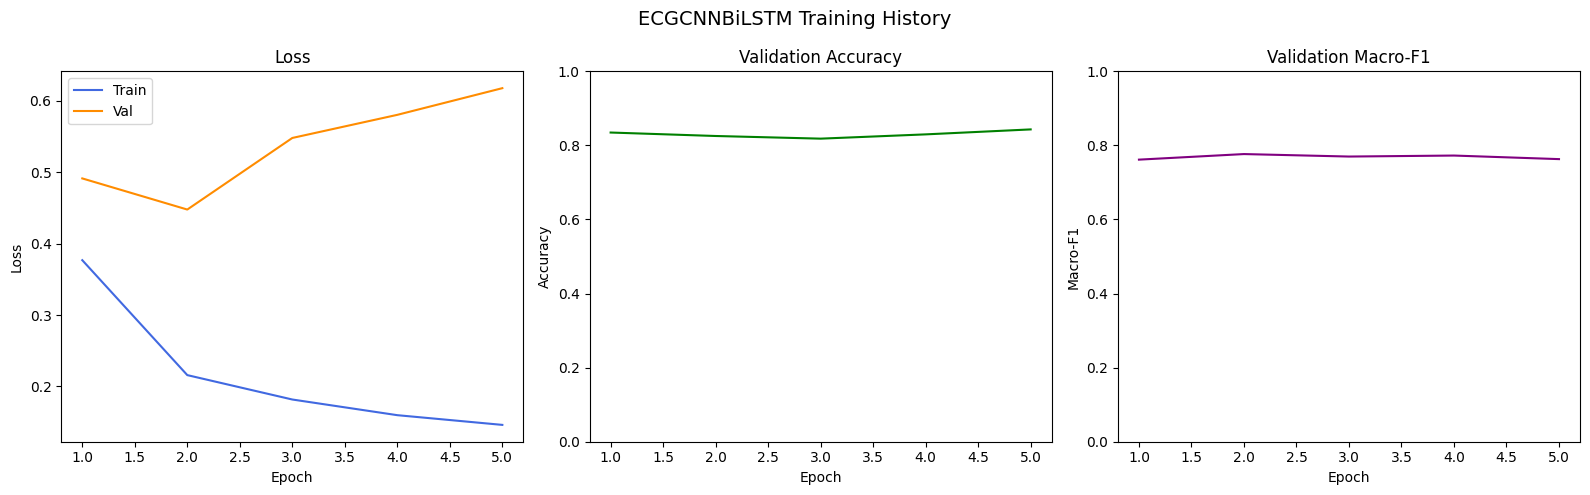

In [4]:
# ---- Plot training curves ----
history = trainer._history  # stored by Trainer.run()

epochs = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Loss
axes[0].plot(epochs, history['train_loss'], label='Train', color='royalblue')
axes[0].plot(epochs, history['val_loss'],   label='Val',   color='darkorange')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend()

# Accuracy
axes[1].plot(epochs, history['val_accuracy'], color='green')
axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)

# Macro-F1
axes[2].plot(epochs, history['val_macro_f1'], color='purple')
axes[2].set_title('Validation Macro-F1')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Macro-F1')
axes[2].set_ylim(0, 1)

plt.suptitle('ECGCNNBiLSTM Training History', fontsize=14)
plt.tight_layout()
plt.show()

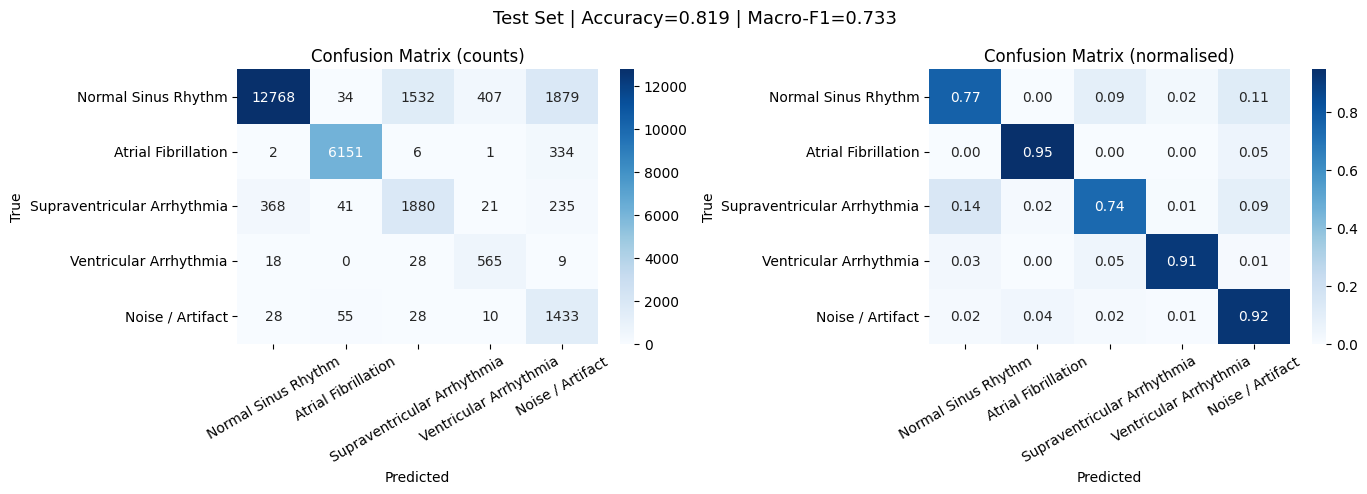

In [5]:
# ---- Confusion matrix on test set ----
cm = test_metrics['confusion_matrix']
class_labels = list(config.CLASS_NAMES.values())

# Normalise per row (recall per class)
cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title, fmt in [
    (axes[0], cm,      'Confusion Matrix (counts)',    'd'),
    (axes[1], cm_norm, 'Confusion Matrix (normalised)', '.2f'),
]:
    sns.heatmap(
        data, annot=True, fmt=fmt, cmap='Blues',
        xticklabels=class_labels, yticklabels=class_labels, ax=ax
    )
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', rotation=0)

plt.suptitle(f'Test Set | Accuracy={test_metrics["accuracy"]:.3f} | Macro-F1={test_metrics["macro_f1"]:.3f}', fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
# ---- Per-class precision / recall / F1 from confusion matrix ----
from sklearn.metrics import classification_report
import torch
from torch.utils.data import DataLoader
import torch.nn as nn
from train import evaluate as eval_fn

# Reload best model
model = build_model(DEVICE)
ckpt  = torch.load(config.BEST_MODEL_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['model_state'])
model.eval()

test_loader = DataLoader(test_ds, batch_size=config.BATCH_SIZE, shuffle=False)

all_preds, all_labels = [], []
with torch.no_grad():
    for X_b, y_b in test_loader:
        logits = model(X_b.to(DEVICE))
        preds  = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds.tolist())
        all_labels.extend(y_b.numpy().tolist())

# Explicitly specify labels and zero_division=0 to safely handle any absent classes
print(classification_report(
    all_labels, all_preds,
    labels=list(config.CLASS_NAMES.keys()),
    target_names=list(config.CLASS_NAMES.values()),
    digits=4,
    zero_division=0,
))


C:\Users\itspr\AppData\Local\Temp\ipykernel_15168\3394824479.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt  = torch.load(config.BEST_MODEL_PATH, map_location=DEV

                             precision    recall  f1-score   support

        Normal Sinus Rhythm     0.9684    0.7682    0.8568     16620
        Atrial Fibrillation     0.9793    0.9472    0.9630      6494
Supraventricular Arrhythmia     0.5412    0.7387    0.6247      2545
     Ventricular Arrhythmia     0.5627    0.9113    0.6958       620
           Noise / Artifact     0.3684    0.9221    0.5265      1554

                   accuracy                         0.8191     27833
                  macro avg     0.6840    0.8575    0.7333     27833
               weighted avg     0.8894    0.8191    0.8383     27833

